# Liver Patient Disease Prediction

## Project Overview
This project focuses on analyzing patient health records and developing machine learning classification models to predict liver disease.

### Objectives
1. Perform Exploratory Data Analysis (EDA).
2. Clean and preprocess the dataset.
3. Train multiple classification algorithms.
4. Compare model performance.
5. Explain the model design and challenges faced.

In [3]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Load the Dataset


In [4]:
# Define column names because the original CSV has no headers

columns = [
    'Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin',
    'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
    'Aspartate_Aminotransferase', 'Total_Proteins',
    'Albumin', 'Albumin_and_Globulin_Ratio', 'Dataset'
]

# Load the dataset
file_path = r"C:\Users\Rakshitha\Downloads\PRCP-1007-LiverPatientPred\Data\Indian Liver Patient Dataset (ILPD).csv"

df = pd.read_csv(file_path, header=None, names=columns)

# Display dataset
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


## 3. Dataset Information and Data Types


In [5]:
# Check dataset information
df.info()

# Check statistical summary
display(df.describe())

# Check dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Proteins              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Dataset
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


Number of Rows: 583
Number of Columns: 11


## 4. Missing Values Analysis

In [6]:
# Check missing values in each column

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(df)) * 100
})

display(missing_report)

print("Total Missing Values:", df.isnull().sum().sum())


,Missing Values,Missing Percentage
Age,0,0.000000
Gender,0,0.000000
Total_Bilirubin,0,0.000000
Direct_Bilirubin,0,0.000000
Alkaline_Phosphotase,0,0.000000
Alamine_Aminotransferase,0,0.000000
Aspartate_Aminotransferase,0,0.000000
Total_Proteins,0,0.000000
Albumin,0,0.000000
Albumin_and_Globulin_Ratio,4,0.686106


Total Missing Values: 4


## 5. Duplicate Records Analysis

In [8]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)


Number of Duplicate Records: 13


## 6. Target Variable Distribution

Target Class Distribution:
1 = Liver Disease
2 = No Liver Disease


Dataset
1    416
2    167
Name: count, dtype: int64

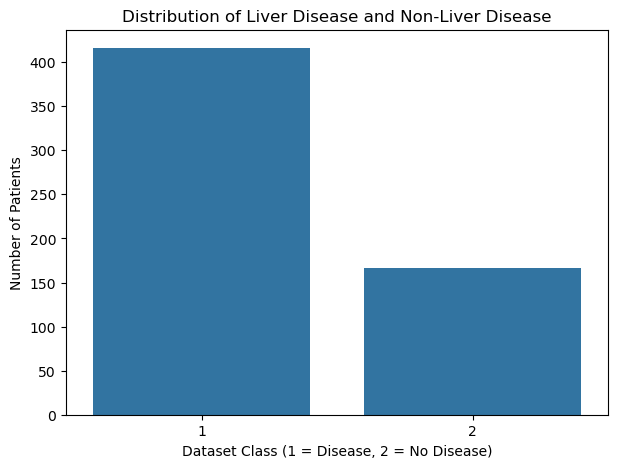

In [9]:
# Check target class distribution

target_counts = df['Dataset'].value_counts().sort_index()

print("Target Class Distribution:")
print("1 = Liver Disease")
print("2 = No Liver Disease")

display(target_counts)

# Visualize target distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Dataset')
plt.title('Distribution of Liver Disease and Non-Liver Disease')
plt.xlabel('Dataset Class (1 = Disease, 2 = No Disease)')
plt.ylabel('Number of Patients')
plt.show()


## 7. Gender Distribution Analysis

Gender Distribution:


Gender
Male      441
Female    142
Name: count, dtype: int64

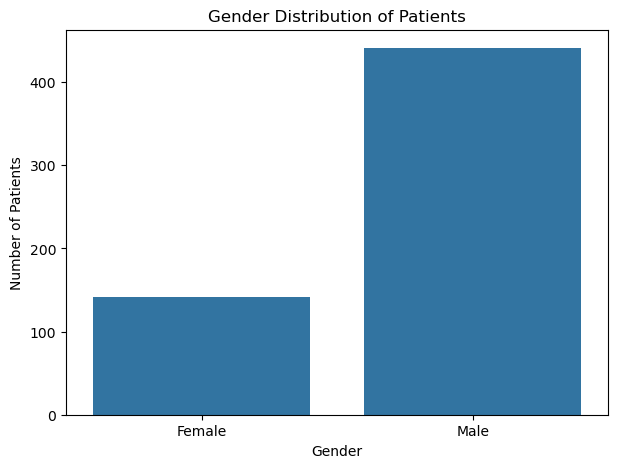

In [10]:
# Analyze gender distribution

gender_counts = df['Gender'].value_counts()

print("Gender Distribution:")
display(gender_counts)

# Visualize gender distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Gender')
plt.title('Gender Distribution of Patients')
plt.xlabel('Gender')
plt.ylabel('Number of Patients')
plt.show()


## 8. Age Distribution Analysis

Age Statistics:


count    583.000000
mean      44.746141
std       16.189833
min        4.000000
25%       33.000000
50%       45.000000
75%       58.000000
max       90.000000
Name: Age, dtype: float64

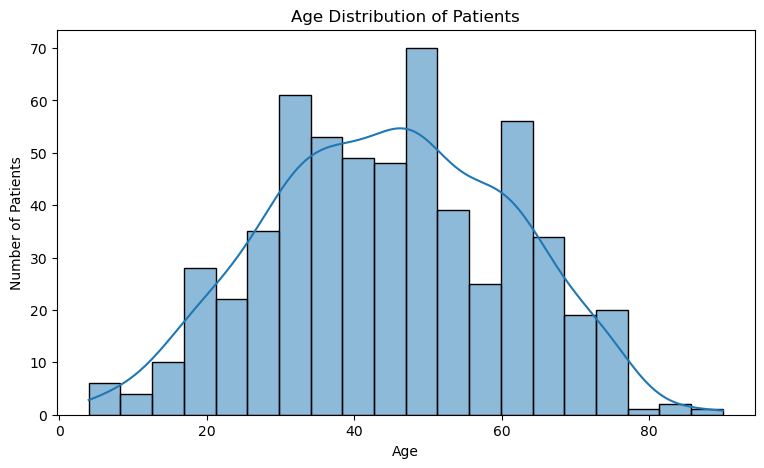

In [11]:
# Analyze age distribution

print("Age Statistics:")
display(df['Age'].describe())

# Visualize age distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Age', bins=20, kde=True)
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.show()


## 9. Distribution of Numerical Features

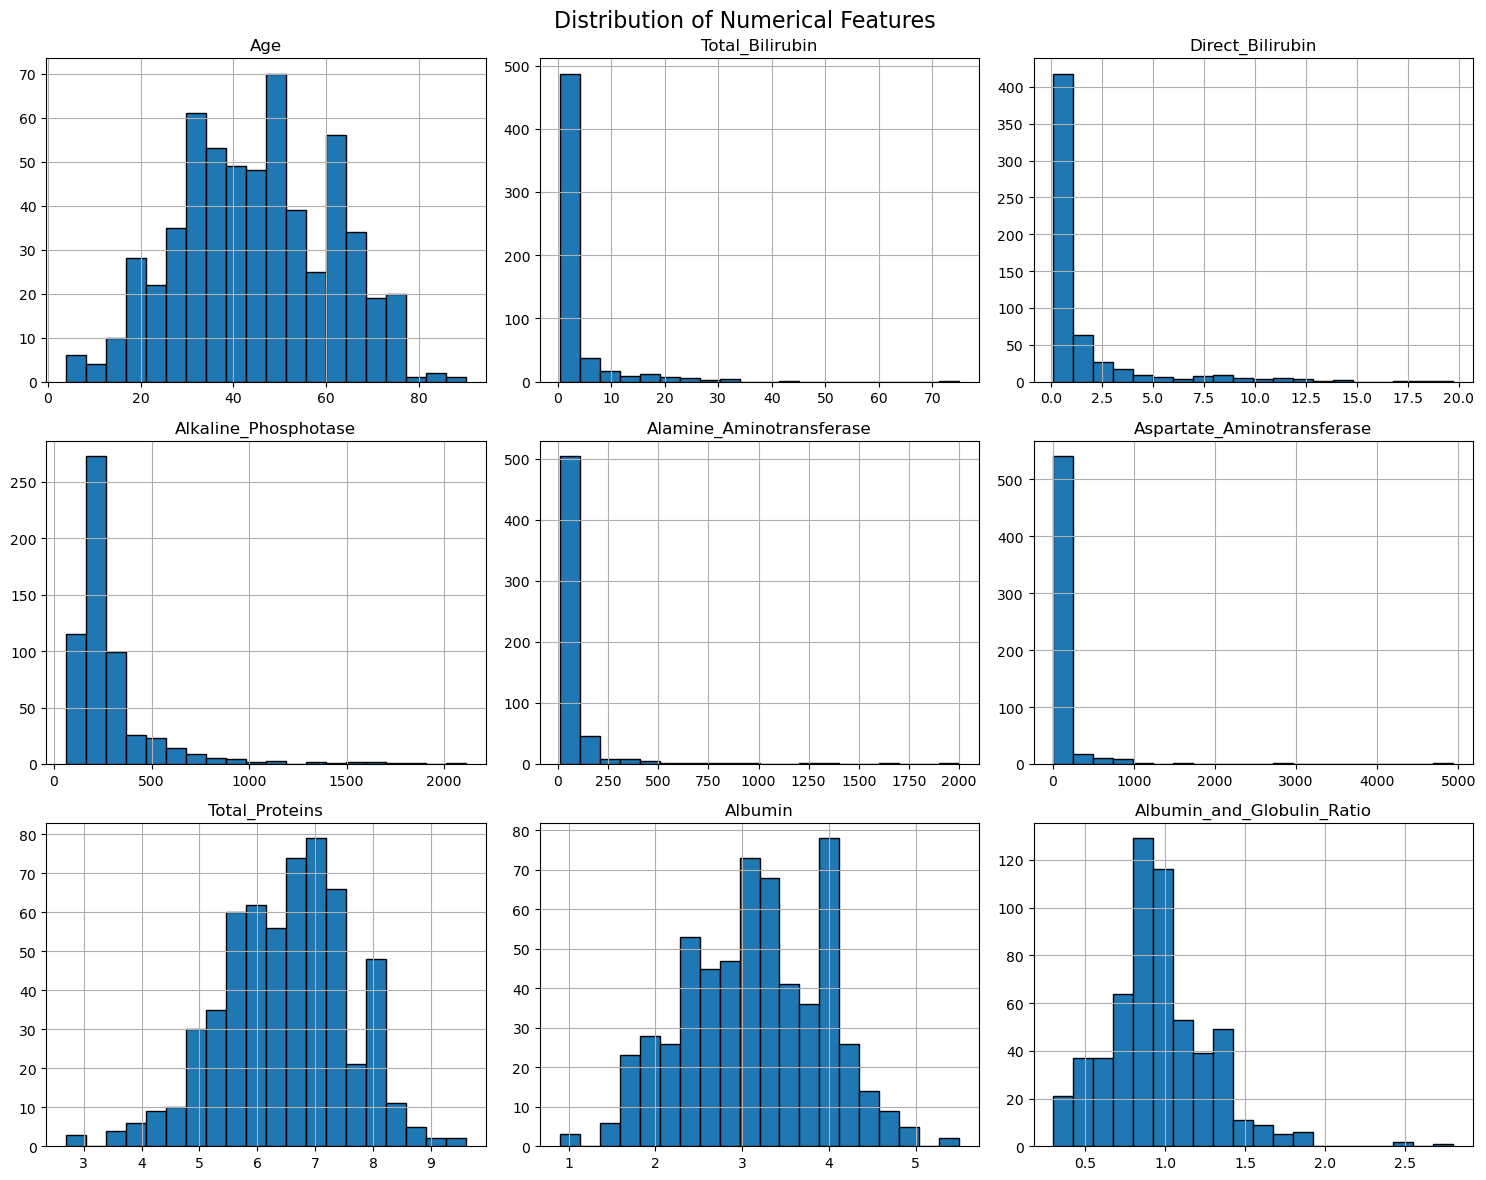

In [12]:
# Visualize distributions of numerical features

numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.drop('Dataset')

df[numerical_features].hist(figsize=(15, 12), bins=20, edgecolor='black')

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()


## 10. Outlier Analysis

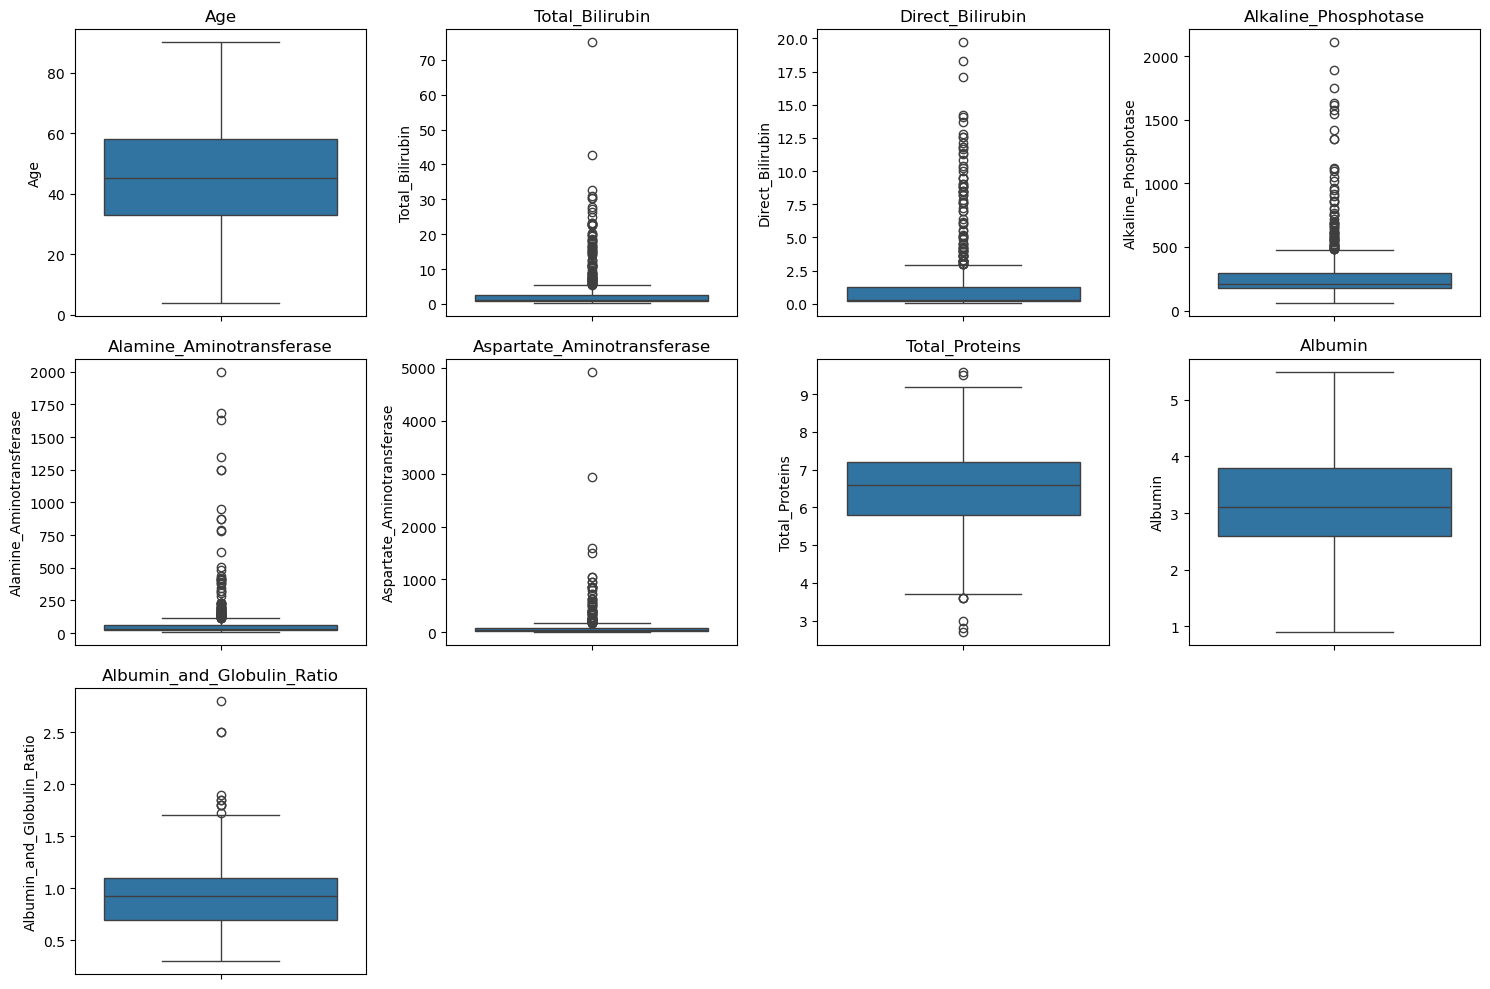

In [13]:
# Visualize outliers in numerical features

plt.figure(figsize=(15, 10))

for index, column in enumerate(numerical_features, 1):
    plt.subplot(3, 4, index)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()


## 11. Correlation Analysis

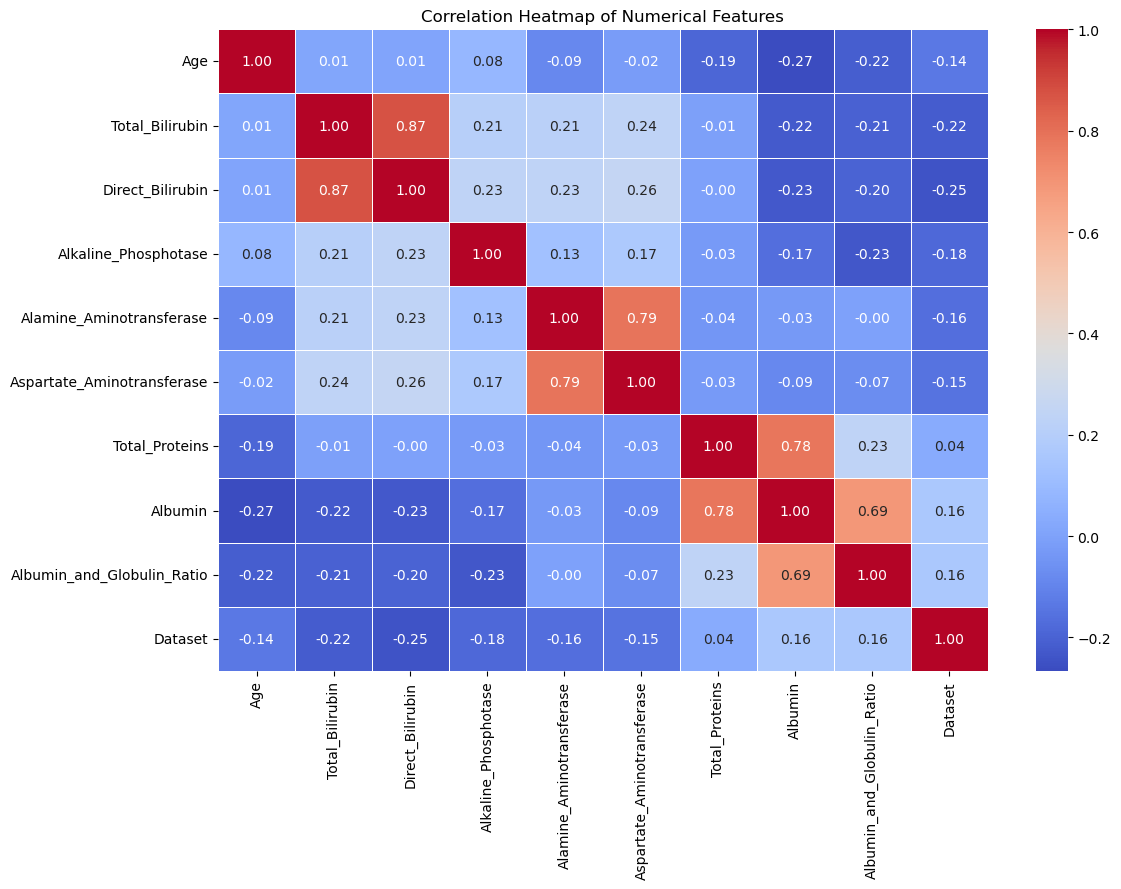

In [14]:
# Analyze correlation between numerical features

plt.figure(figsize=(12, 9))

correlation_matrix = df.select_dtypes(include=['int64', 'float64']).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()


## 12. Data Cleaning and Missing Value Treatment

In [15]:
# Fill missing values using median

median_value = df['Albumin_and_Globulin_Ratio'].median()

df['Albumin_and_Globulin_Ratio'] = df['Albumin_and_Globulin_Ratio'].fillna(median_value)

print("Missing values after treatment:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing values after treatment:
Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Proteins                0
Albumin                       0
Albumin_and_Globulin_Ratio    0
Dataset                       0
dtype: int64

Total Missing Values: 0


## 13. Handling Duplicate Records

In [16]:
# Remove duplicate records from the working DataFrame

print("Records before removing duplicates:", df.shape[0])

df = df.drop_duplicates().copy()

print("Records after removing duplicates:", df.shape[0])
print("Duplicate records remaining:", df.duplicated().sum())


Records before removing duplicates: 583
Records after removing duplicates: 570
Duplicate records remaining: 0


## 14. Target Variable Encoding

In [17]:
# Convert target variable into binary format

df['Liver_Disease'] = df['Dataset'].map({1: 1, 2: 0})

# Check target distribution
print("Updated Target Distribution:")
print(df['Liver_Disease'].value_counts())

# Remove original target column
df.drop(columns=['Dataset'], inplace=True)

print("\nUpdated Dataset Shape:", df.shape)
display(df.head())


Updated Target Distribution:
Liver_Disease
1    406
0    164
Name: count, dtype: int64

Updated Dataset Shape: (570, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Liver_Disease
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [18]:
# Final data quality check

print("Total Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

print("\nDataset Shape:", df.shape)
print("\nTarget Distribution:")
print(df['Liver_Disease'].value_counts())


Total Missing Values: 0
Duplicate Records: 0

Dataset Shape: (570, 11)

Target Distribution:
Liver_Disease
1    406
0    164
Name: count, dtype: int64


## 15. Feature and Target Separation

In [27]:
# Separate input features and target variable

X = df.drop(columns=['Liver_Disease'])
y = df['Liver_Disease']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Feature Names:")
print(X.columns.tolist())


Input Features Shape: (570, 10)
Target Variable Shape: (570,)

Input Feature Names:
['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Proteins', 'Albumin', 'Albumin_and_Globulin_Ratio']


## 16. Splitting Training and Testing Data

In [28]:
# Import train_test_split

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Features: (456, 10)
Testing Features: (114, 10)
Training Target: (456,)
Testing Target: (114,)

Training Target Distribution:
Liver_Disease
1    325
0    131
Name: count, dtype: int64

Testing Target Distribution:
Liver_Disease
1    81
0    33
Name: count, dtype: int64


## 17. Feature Preprocessing

In [29]:
# Import preprocessing libraries

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Identify numerical and categorical features

numerical_columns = X.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = X.select_dtypes(include=['object']).columns

# Create preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ]
)

print("Numerical Features:", list(numerical_columns))
print("Categorical Features:", list(categorical_columns))
print("\nPreprocessing transformer created successfully!")



Numerical Features: ['Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Proteins', 'Albumin', 'Albumin_and_Globulin_Ratio']
Categorical Features: ['Gender']

Preprocessing transformer created successfully!



## 18. Model Training and Comparison

In [30]:
# Import classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Define classification models

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(class_weight='balanced', probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=200, class_weight='balanced', random_state=42)
}

print("Total Classification Models:", len(models))
print("\nModels:")
for model_name in models:
    print(model_name)
    

Total Classification Models: 7

Models:
Logistic Regression
Decision Tree
Random Forest
KNN
SVM
Gradient Boosting
Extra Trees


## 19. Training Classification Models

In [23]:
# Train all classification models

trained_models = {}

for model_name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[model_name] = pipeline

    print(model_name, "trained successfully!")

print("\nAll models trained successfully!")


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
KNN trained successfully!
SVM trained successfully!
Gradient Boosting trained successfully!
Extra Trees trained successfully!

All models trained successfully!


## 20. Model Comparison Using Cross-Validation

In [31]:
# Import cross-validation tools

from sklearn.model_selection import StratifiedKFold, cross_validate

# Define stratified 5-fold cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Evaluate all models using cross-validation

cv_results = []

for model_name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        'Model': model_name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean(),
        'ROC AUC': scores['test_roc_auc'].mean()
    })

# Display comparison report

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.round(4))



,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.6316,0.8634,0.5754,0.6873,0.7182
1,Decision Tree,0.6513,0.7539,0.7569,0.7546,0.5732
2,Random Forest,0.7126,0.7553,0.8831,0.8141,0.7182
3,KNN,0.6732,0.7459,0.8215,0.7818,0.6316
4,SVM,0.6008,0.8897,0.5046,0.6401,0.7132
5,Gradient Boosting,0.6974,0.7631,0.8369,0.7976,0.6936
6,Extra Trees,0.7148,0.7552,0.8862,0.8150,0.7247


## 21. Final Model Evaluation

Selected Model: Extra Trees

Final Test Performance:
Accuracy: 0.7192982456140351
Precision: 0.7378640776699029
Recall: 0.9382716049382716
F1 Score: 0.8260869565217391
ROC AUC: 0.7854470632248409

Classification Report:
                  precision    recall  f1-score   support

No Liver Disease       0.55      0.18      0.27        33
   Liver Disease       0.74      0.94      0.83        81

        accuracy                           0.72       114
       macro avg       0.64      0.56      0.55       114
    weighted avg       0.68      0.72      0.67       114



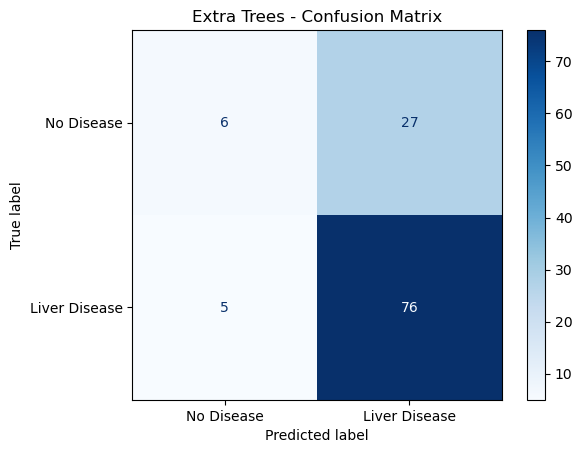

In [33]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Select the best model based on cross-validation F1 Score

best_model_name = cv_comparison.loc[
    cv_comparison['F1 Score'].idxmax(), 'Model'
]

best_model = trained_models[best_model_name]

# Predict using unseen test data

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics

print("Selected Model:", best_model_name)

print("\nFinal Test Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['No Liver Disease', 'Liver Disease']
))

# Plot confusion matrix

cm = confusion_matrix(y_test, y_pred)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Disease', 'Liver Disease']
)

display_matrix.plot(cmap='Blues')
plt.title('Extra Trees - Confusion Matrix')
plt.show()


## 22. ROC Curve Analysis

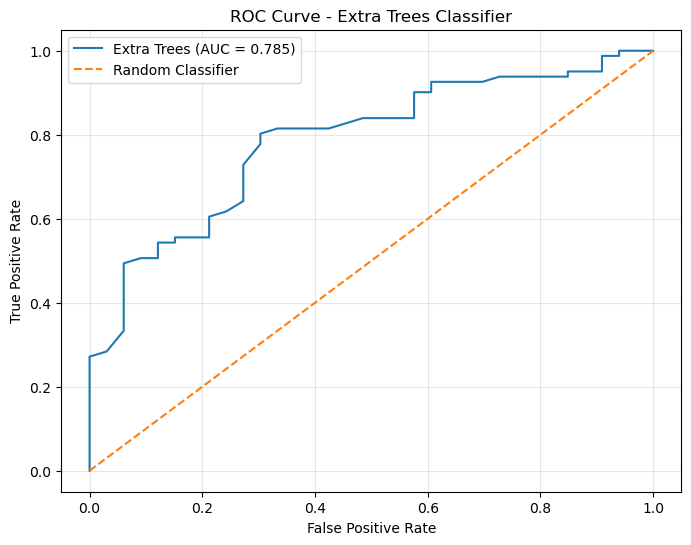

In [28]:
# Import ROC curve functions

from sklearn.metrics import roc_curve, auc

# Calculate ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

# Plot ROC curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Extra Trees (AUC = {roc_auc:.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Extra Trees Classifier')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 23. Feature Importance Analysis

,Feature,Importance
1,Gender,0.0135
0,Age,0.0055
4,Alkaline_Phosphotase,0.0054
5,Alamine_Aminotransferase,-0.0003
6,Aspartate_Aminotransferase,-0.0055
3,Direct_Bilirubin,-0.0078
2,Total_Bilirubin,-0.0088
7,Total_Proteins,-0.0090
8,Albumin,-0.0105
9,Albumin_and_Globulin_Ratio,-0.0121


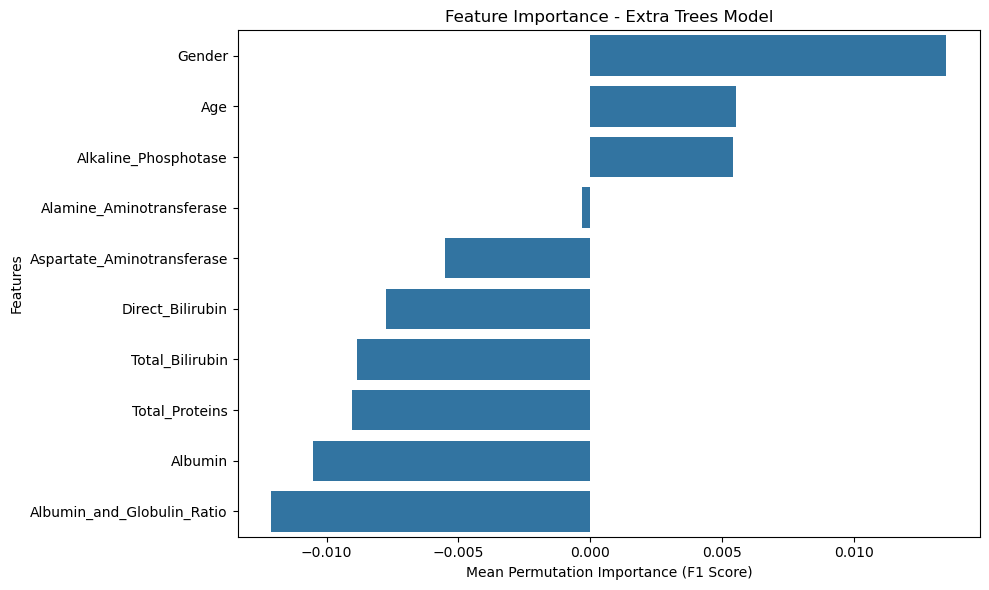

In [34]:
# Calculate feature importance using permutation importance

from sklearn.inspection import permutation_importance

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='f1'
)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

display(feature_importance.round(4))

# Visualize feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Extra Trees Model')
plt.xlabel('Mean Permutation Importance (F1 Score)')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## 24. Model Performance Comparison

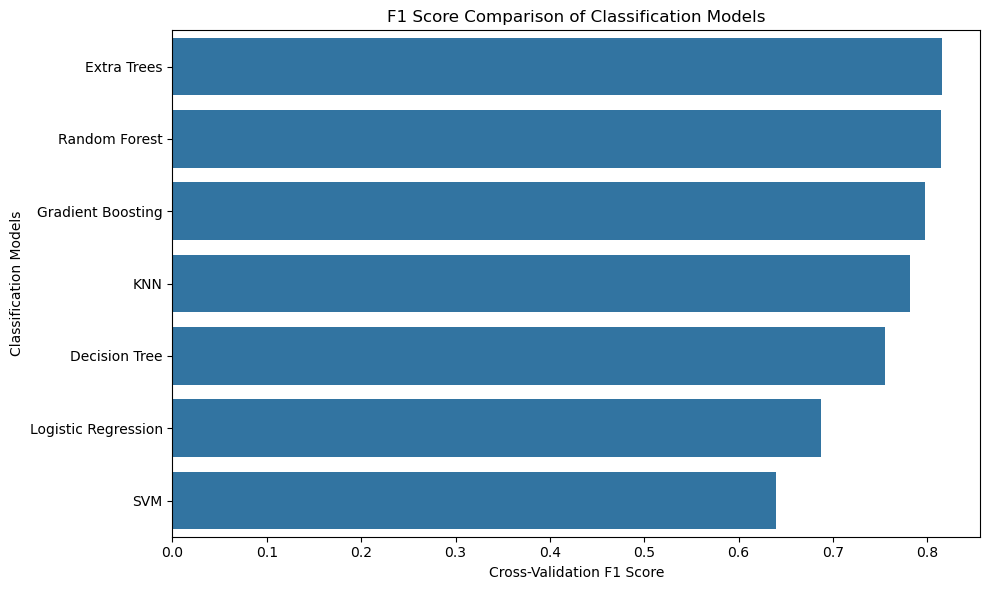

In [35]:
# Compare model performance using F1 Score

plt.figure(figsize=(10, 6))

sns.barplot(
    data=cv_comparison.sort_values('F1 Score', ascending=False),
    x='F1 Score',
    y='Model'
)

plt.title('F1 Score Comparison of Classification Models')
plt.xlabel('Cross-Validation F1 Score')
plt.ylabel('Classification Models')
plt.tight_layout()
plt.show()


## 25. Overall Model Performance Comparison

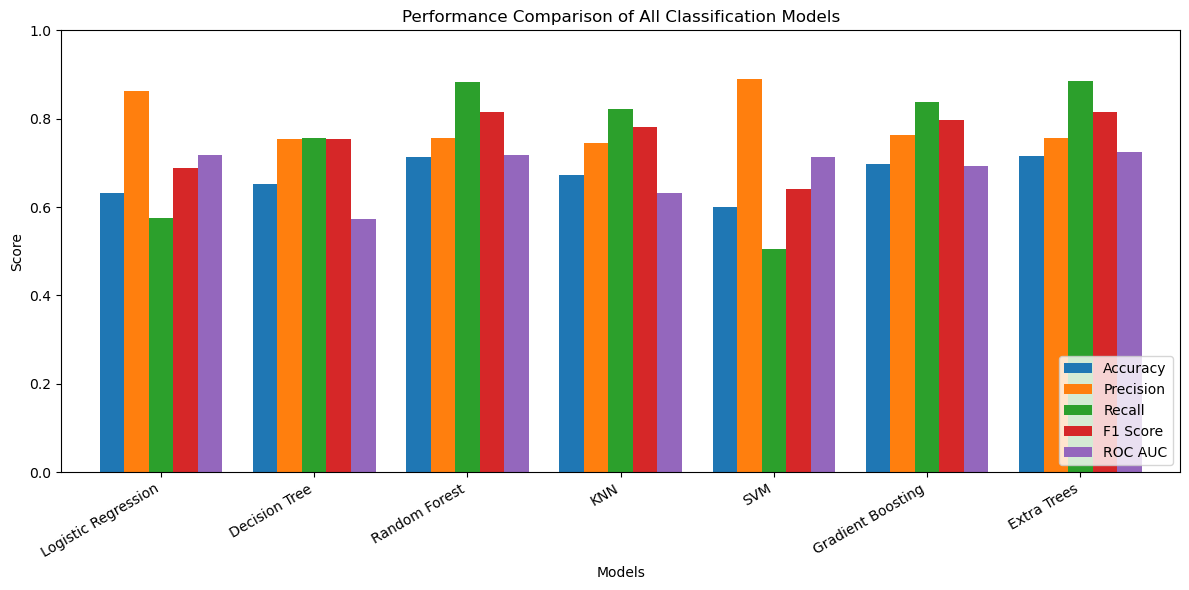

In [36]:
# Compare all evaluation metrics across models

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']

cv_comparison.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Performance Comparison of All Classification Models')
plt.ylabel('Score')
plt.xlabel('Models')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## Model Design and Algorithm Selection

### Basis for Model Design

The project was designed as a binary classification problem to predict whether a patient has liver disease.

- **Logistic Regression:** Selected as a baseline classification algorithm.
- **Decision Tree:** Used to identify nonlinear decision patterns.
- **Random Forest:** Used to combine multiple decision trees and improve generalization.
- **KNN:** Used to classify patients based on similarities between observations.
- **SVM:** Used to identify an effective decision boundary between classes.
- **Gradient Boosting:** Used to improve predictions through sequential learning.
- **Extra Trees:** Used to explore randomized decision trees and compare their predictive performance.

### Preprocessing and Evaluation Strategy

OneHotEncoder was used for categorical data, while StandardScaler was applied to numerical features. Stratified train-test splitting preserved the target-class proportions.

Five-fold stratified cross-validation was used to compare the classifiers. F1 score was considered for model selection because the dataset has an imbalanced target distribution.

Extra Trees was selected because it achieved the highest cross-validation F1 score.

## 26. Challenges Faced During the Project

### 1. Missing Values
Four missing values were identified in the Albumin and Globulin Ratio column. Median imputation was used to handle them.

### 2. Duplicate Records
Thirteen duplicate records were identified and removed to avoid repeated observations.

### 3. Class Imbalance
The dataset contained more liver disease cases than non-disease cases. Stratified train-test splitting and class weighting were used where supported.

### 4. Categorical Data
Gender was a categorical feature. OneHotEncoder was used to convert it into numerical format.

### 5. Different Feature Scales
Numerical features had different measurement ranges. StandardScaler was used to standardize them.

### 6. Model Performance
Different classifiers produced different results. Cross-validation was used to compare models, and Extra Trees was selected based on its highest F1 score.

### 7. Minority Class Prediction
The selected model showed low recall for the No Liver Disease class. This indicates scope for further improvement.

## 27. Complete Data Analysis Report

### Dataset Summary
- Original records: 583
- Duplicate records removed: 13
- Final records: 570
- Input features: 10
- Target variable: Liver_Disease

### Target Distribution
- Liver Disease: 406 patients
- No Liver Disease: 164 patients

### Data Cleaning
- Four missing values handled using median imputation.
- Thirteen duplicate records removed.
- Gender encoded using OneHotEncoder.
- Numerical features standardized using StandardScaler.

### Exploratory Data Analysis
- Gender distribution analyzed.
- Age distribution visualized.
- Numerical feature distributions examined.
- Outliers investigated using boxplots.
- Correlations analyzed using a heatmap.



## 28. Project Conclusion

The Liver Patient Disease Prediction project involved exploratory data analysis, data cleaning, feature preprocessing, and machine learning classification.

Seven classification algorithms were trained and compared using 5-fold stratified cross-validation.

Extra Trees Classifier achieved the highest cross-validation F1 score of 0.8150.

On the unseen test dataset, it achieved:
- Accuracy: 71.93%
- Precision: 73.79%
- Recall: 93.83%
- F1 Score: 82.61%
- ROC AUC: 78.54%

The model identified most liver disease cases but showed limited performance in identifying patients without liver disease.

This project demonstrates the application of machine learning techniques to healthcare data analysis. The model is intended for educational purposes and requires further validation before any real-world clinical use.